# 고장 라벨 후보와 불확실성

라벨은 60~600 원시시간 단위의 진단 후보입니다. 실제 초 단위·정비 종료·Fault 이력 유효범위가 미확정이므로 확정 학습 라벨은 없습니다.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert ROOT.name == 'PHM2018-Project-V2'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / 'outputs/matplotlib')
import polars as pl
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
figdir = ROOT / 'reports/figures'
figdir.mkdir(parents=True, exist_ok=True)
load = lambda name: json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


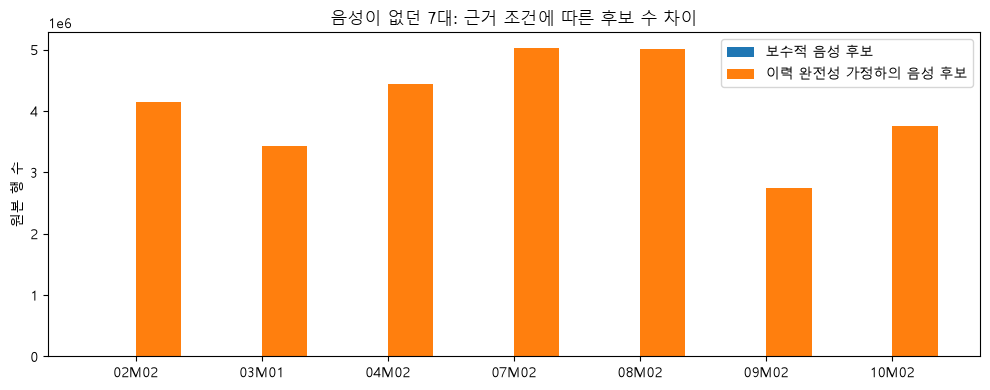

{'f1_h300': {'positive': 15768,
  'negative': 62004004,
  'NA': 20165908,
  'excluded_lt60': 3760},
 'f1_h600': {'positive': 37468,
  'negative': 61982304,
  'NA': 20165908,
  'excluded_lt60': 3760},
 'f1_h1800': {'positive': 135788,
  'negative': 61883984,
  'NA': 20165908,
  'excluded_lt60': 3760},
 'f2_h300': {'positive': 5100,
  'negative': 55991405,
  'NA': 26191715,
  'excluded_lt60': 1220},
 'f2_h600': {'positive': 11225,
  'negative': 55985280,
  'NA': 26191715,
  'excluded_lt60': 1220},
 'f2_h1800': {'positive': 35023,
  'negative': 55961482,
  'NA': 26191715,
  'excluded_lt60': 1220},
 'f3_h300': {'positive': 4138,
  'negative': 38118071,
  'NA': 44066194,
  'excluded_lt60': 1037},
 'f3_h600': {'positive': 9444,
  'negative': 38112765,
  'NA': 44066194,
  'excluded_lt60': 1037},
 'f3_h1800': {'positive': 31003,
  'negative': 38091206,
  'NA': 44066194,
  'excluded_lt60': 1037},
 'any_h300': {'positive': 24842,
  'negative': 29840709,
  'NA': 52317885,
  'excluded_lt60': 6004}

In [2]:
audit = load('audit_summary.json')
seven = {'02M02','03M01','04M02','07M02','08M02','09M02','10M02'}
selected = [a for a in audit if a['tool'] in seven]
x = list(range(len(selected)))
fig, ax = plt.subplots(figsize=(10,4))
ax.bar([i-.18 for i in x], [a['distributions_raw']['any_h600']['negative'] for a in selected], width=.36, label='보수적 음성 후보')
ax.bar([i+.18 for i in x], [a['sensitivity_any']['h600']['negative'] for a in selected], width=.36, label='이력 완전성 가정하의 음성 후보')
ax.set_xticks(x, [a['tool'] for a in selected]); ax.set_ylabel('원본 행 수'); ax.legend()
ax.set_title('음성이 없던 7대: 근거 조건에 따른 후보 수 차이')
fig.tight_layout(); fig.savefig(figdir / '02_seven_tools.png', dpi=130); plt.show()
load('label_distribution_raw.json')

## 그래프 해석과 한계

대안 음성이 늘어나는 것은 정상 운전이 검증되었다는 뜻이 아닙니다. 세 유형의 유한 TTF를 모두 요구하는 조건과 이력 완전성 가정의 차이입니다. TTF Null을 자동으로 정상으로 바꾸지 않았으며 대안은 학습용으로 배포하지 않습니다.

상세 결과는 `reports/`의 한국어 보고서와 `outputs/`의 수치 파일을 참조하세요.